# Tien leerbare schaalfactoren per MX-groep / A32
## SVHN · CNN-8 · honderd epochs · schaalkeuzes leren tot epoch 100

Iedere groep van **32 gewichten** kiest één factor uit **×1, ×2, ×4, ×8, ×16, ×32, ×64, ×128, ×256 en ×512**. De E4M3-bron wordt uit de FP32-master bepaald met dezelfde preprocessing en encoder als eerder. E2M3 behoudt de hoogste twee exponentbits; E2M1 ontstaat door twee mantissabits van E2M3 te verwijderen. Beide lagere modi delen **E8M0-broncode + gekozen offset 0..9**. De E4M3-bronschaal zelf wordt niet geleerd.

De **4.080 FP32-hulpwaarden** $\theta_b$ beginnen exact op **6**, dus aanvankelijk ×64, zonder extra willekeurige initialisatie. Hun bereik is $[0,9]$. De forward rondt af naar het dichtstbijzijnde gehele getal; halve waarden gaan naar de hogere offset. De benaderde schaalgradient is $\ln(2)\sum_{i\in b}g_iq_i$ per lagere modus. De twee bijdragen worden opgeteld. Na één gezamenlijke Adam-update worden de hulpwaarden teruggebracht binnen $[0,9]$. Activaties zijn **A32**, masters en optimizerstaat **FP32**.

Dit experiment begint **opnieuw vanaf nul** met dezelfde opzet als de geslaagde vijf-epochpilot. Gewichten én schaalhulpwaarden leren gedurende **alle honderd epochs**. De leersnelheid daalt voor beide groepen na epochs 50/75/90. Checkpoint50 wordt volledig bewaard, zodat een eventuele latere tak met bevroren offsets vanuit exact die staat kan vertrekken. Die tak wordt hier niet uitgevoerd.

Dit notebook leest alleen JSON/CSV. Het start geen training, opent geen dataset en laadt geen modelcheckpoint. De hoofdvergelijking gebruikt de echte eerdere **binaire honderd-epochtraining met leren tot 100** en de **vaste ×32/×64-trainingen**. De nieuwe vijf-epochpilot staat apart als vroege controle. De template wordt zonder uitgevoerde cellen geleverd. Voer zelf **Run All** uit.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_learned_scale10_reference100\\20261104_193228_406260_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# De helper werkt vanuit de pakketmap, projectroot, resultaatmap of uitgepakte feedbackmap.
roots = []
if RUN_DIR is not None and Path(RUN_DIR).expanduser().is_dir():
    roots.append(Path(RUN_DIR).expanduser().resolve())
roots += [Path.cwd(), *Path.cwd().parents]
candidates = []
for root in dict.fromkeys(roots):
    candidates += [root / 'notebook_support.py',
                   root / 'software_checks' / 'mx_triple_learned_scale10_reference100_v1' / 'notebook_support.py',
                   root / 'runner_source' / 'notebook_support.py']
helper_path = next((p for p in candidates if p.is_file()), None)
if helper_path is None:
    raise FileNotFoundError('Houd notebook_support.py bij de notebook of open vanuit de projectmap.')
helper_name = '_mx_triple_learned_scale10_reference100_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
print('Ingelezen resultaatmap:', run.path)
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_learned_scale10_reference100\20261104_193228_406260_joint_run


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **100**.

**Alle honderd epochs voor alle drie modi aanwezig; volledige referentie volgens het runrapport.** Epoch 100 staat naast het door E4M3 gekozen beste checkpoint.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,Actuele E4M3-bron → exponent-MSB-truncatie naa...
2,Geleerde correctie,"Eén FP32 θ per B32-groep; θ∈[0,9], begin6; afr..."
3,Gedeelde lagere schaal,E2M3 en E2M1 delen dezelfde blokkeuze. De E4M3...
4,Mastergradient,"Identity-STE naar G(W), zonder extra schaalfac..."
5,Schaalgradient,ln(2) × som(gradient_q × werkelijk gebruikt q)...
6,Gradientnormalisatie,Geen extra LSQ-normalisatie; geen gemiddelde i...
7,Schaalgrenzen,"θ na Adam projecteren op [0,9]; E8M0-code in b..."
8,Trainbare parameters,132954 basis + 4080 schaalproxies = 137034
9,Activaties / masters / proxies,A32 / FP32 / FP32


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch100 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy binnen de gemeten training**. Een gelijke score vervangt het eerdere checkpoint niet. E2M3 en E2M1 worden op precies dezelfde epoch gerapporteerd; hun eigen hoogste scores worden niet samengevoegd met een andere E4M3-epoch.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. De beste score is daardoor geen onafhankelijke testschatting na selectie. Het vaste eindpunt **epoch 100** staat er apart naast zodra de volledige training technisch is bevestigd. Bij een onvoltooide run is het eerste paneel uitdrukkelijk de laatste afgeronde epoch; er wordt geen ontbrekende epoch 100-score ingevuld.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Epoch 100,100,MXFP8_E4M3,94.871696,24.697 / 26.032,0.211089,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Epoch 100,100,MXFP6_E2M3,93.934388,24.453 / 26.032,0.216024,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Epoch 100,100,MXFP4_E2M1,93.961278,24.460 / 26.032,0.223009,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de g...,63,MXFP8_E4M3,95.029195,24.738 / 26.032,0.205727,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de g...,63,MXFP6_E2M3,93.846036,24.430 / 26.032,0.221264,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de g...,63,MXFP4_E2M1,93.700061,24.392 / 26.032,0.228132,checkpoint_selection.json,best_checkpoint.pt


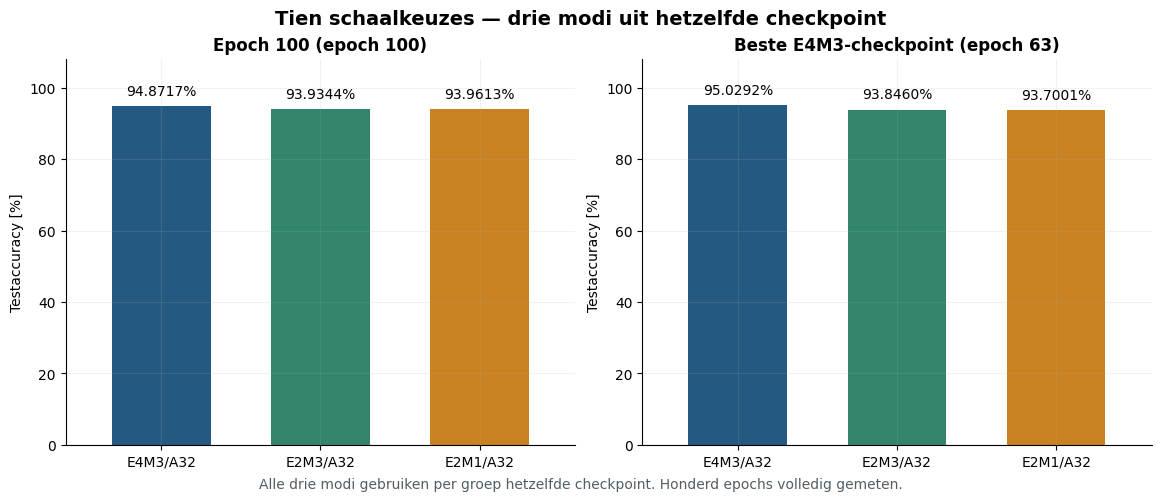

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met twee leerbare keuzes en vaste ×32/×64

Alle hoofdreferenties zijn werkelijk uitgevoerde **honderd-epochtrainingen**. De binaire referentie leert ×32/×64 gedurende alle honderd epochs; zij heeft geen bevriezing op 50. Voor een onvoltooide nieuwe training gebruiken we alleen dezelfde reeds afgeronde epochrange. De meegeleverde bestanden en hun herkomst worden met hashes gecontroleerd.

De grafieken tonen het **volledige accuracyverloop**, de drie accuracies op **epoch 100** en op **het checkpoint gekozen door E4M3 binnen dezelfde gemeten epochrange**. Iedere training kiest haar eigen E4M3-bestepoch; haar drie precisies blijven samen. Er worden geen latere referentie-epochs gebruikt om een kortere run te beoordelen.

De leerbare varianten beginnen op dezelfde factor ×64. De tienkeuzevariant verruimt de toegestane beweging; we voegen geen exploratieruis, extra trainingspasses of extra FP32-schaalparameters toe. Eén run per variant laat geen uitspraak over statistische significantie toe.


### Tien leerbare keuzes tegenover twee keuzes en vaste factoren

Alle drie referenties zijn werkelijk uitgevoerde honderd-epochtrainingen. De binaire referentie leert de keuze ×32/×64 gedurende alle honderd epochs; zij bevriest niet op 50. Een onvoltooide huidige run wordt alleen vergeleken binnen dezelfde reeds afgeronde epochrange. Iedere training kiest daarbinnen één gezamenlijk checkpoint op de E4M3-testaccuracy. 

**Vast ×32: vergelijking bevestigd voor epochs 1–100.**

**Vast ×64: vergelijking bevestigd voor epochs 1–100.**

**Geleerd: 2 keuzes: vergelijking bevestigd voor epochs 1–100.**

De twee leerbare varianten hebben evenveel FP32-schaalparameters en dezelfde initialisatie θ=6. De tienkeuzevariant kan ook boven 6 en onder 5 bewegen. Afzonderlijke CUDA-runs zijn niet bitexact gegarandeerd. Eén run per variant geeft geen statistische significantie of algemene rangschikking. Checkpointselectie gebruikt de officiële testset; de geselecteerde score is geen onafhankelijke eindtest.

,Controlepunt,Referentie,Gewichtsformaat,Epoch tienkeuze,Epoch referentie,Tienkeuze accuracy [%],Referentie accuracy [%],Verschil tienkeuze − referentie [pp],Tienkeuze harde CE,Referentie harde CE
0,Epoch 100,Vast ×32,MXFP8_E4M3,100,100,94.871696,94.706515,0.165181,0.211089,0.205240
1,Epoch 100,Vast ×32,MXFP6_E2M3,100,100,93.934388,94.852489,-0.918101,0.216024,0.186292
2,Epoch 100,Vast ×32,MXFP4_E2M1,100,100,93.961278,94.913952,-0.952674,0.223009,0.187656
3,Beste E4M3 binnen epochs 1–100,Vast ×32,MXFP8_E4M3,63,55,95.029195,94.844806,0.184388,0.205727,0.198763
4,Beste E4M3 binnen epochs 1–100,Vast ×32,MXFP6_E2M3,63,55,93.846036,95.006146,-1.160111,0.221264,0.186000
5,Beste E4M3 binnen epochs 1–100,Vast ×32,MXFP4_E2M1,63,55,93.700061,94.775661,-1.075599,0.228132,0.191920
6,Epoch 100,Vast ×64,MXFP8_E4M3,100,100,94.871696,94.929318,-0.057621,0.211089,0.209868
7,Epoch 100,Vast ×64,MXFP6_E2M3,100,100,93.934388,94.898586,-0.964198,0.216024,0.189969
8,Epoch 100,Vast ×64,MXFP4_E2M1,100,100,93.961278,94.791026,-0.829748,0.223009,0.193797
9,Beste E4M3 binnen epochs 1–100,Vast ×64,MXFP8_E4M3,63,42,95.029195,95.086816,-0.057621,0.205727,0.193877


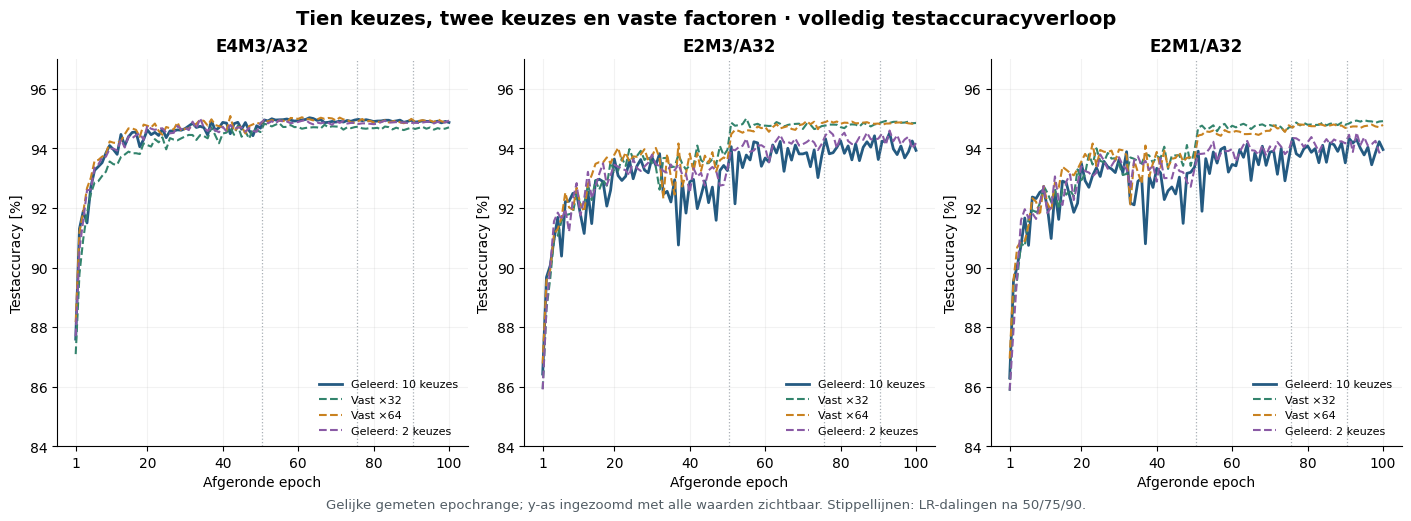

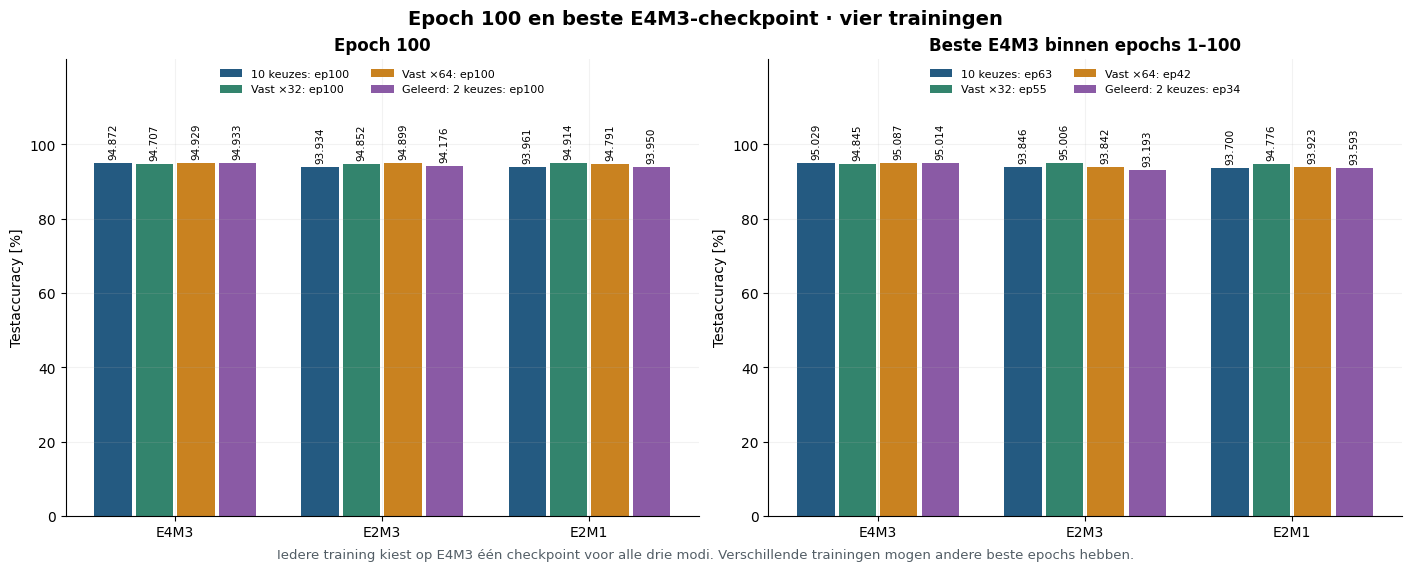

In [4]:
references = ns.load_fixed_references(run)
display(Markdown(ns.comparison_markdown(run, references)))
display(ns.comparison_table(run, references).round(6))
figures['scale_comparison_curves'] = ns.plot_scale_comparison_curves(run, references)
display(figures['scale_comparison_curves'])
plt.close(figures['scale_comparison_curves'])
figures['scale_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, references)
display(figures['scale_comparison_checkpoints'])
plt.close(figures['scale_comparison_checkpoints'])


## Vroege controle tegenover de uitgevoerde tienkeuzepilot

De pilot is een aparte training met hetzelfde recept. De volledige run begint opnieuw bij epoch 0. Hieronder worden alleen de twee epoch 5-metingen vergeleken; het pilotcheckpoint is geen warmstart.


In [5]:
pilot_reference = ns.load_pilot_reference(run)
display(Markdown(ns.pilot_comparison_markdown(run, pilot_reference)))
display(ns.pilot_comparison_table(run, pilot_reference).round(6))


### Afzonderlijke controle met de eerdere tienkeuzepilot

De volledige training begint opnieuw vanaf dezelfde initialisatie. Zij hervat niet vanaf het pilotcheckpoint. Deze tabel vergelijkt uitsluitend epoch 5 zodra die opnieuw is bereikt; de pilot levert geen epoch100-resultaat. De oorspronkelijke CUDA-backend garandeert geen bitexacte herhaling. **Herkomst en vergelijkbare opzet bevestigd.**

,Controlepunt,Gewichtsformaat,Nieuwe volledige run [%],Eerdere pilot [%],Verschil nieuwe run − pilot [pp]
0,Epoch 5,MXFP8_E4M3,92.693608,92.655194,0.038414
1,Epoch 5,MXFP6_E2M3,91.687154,91.425937,0.261217
2,Epoch 5,MXFP4_E2M1,91.664106,91.602643,0.061463


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf een nieuwe initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met de opgeslagen harde blokkeuzes, bevroren evaluatiestaat en volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee. De E4M3-route blijft direct uit de actuele bron bepaald; E2M3 en E2M1 volgen dezelfde geleerde blokkeuze.


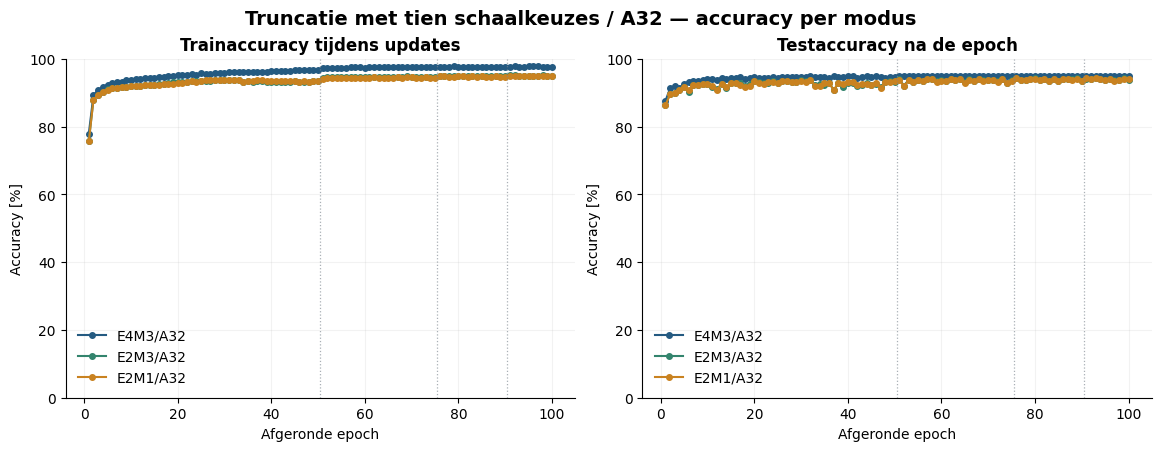

In [6]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.915272
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.882069
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.688920
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.451274
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.443576
...,...,...,...,...,...
595,100,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.190198
596,100,train,MXFP8_E4M3,hard_cross_entropy,0.075734
597,100,test,MXFP4_E2M1,hard_cross_entropy,0.223009
598,100,test,MXFP6_E2M3,hard_cross_entropy,0.216024


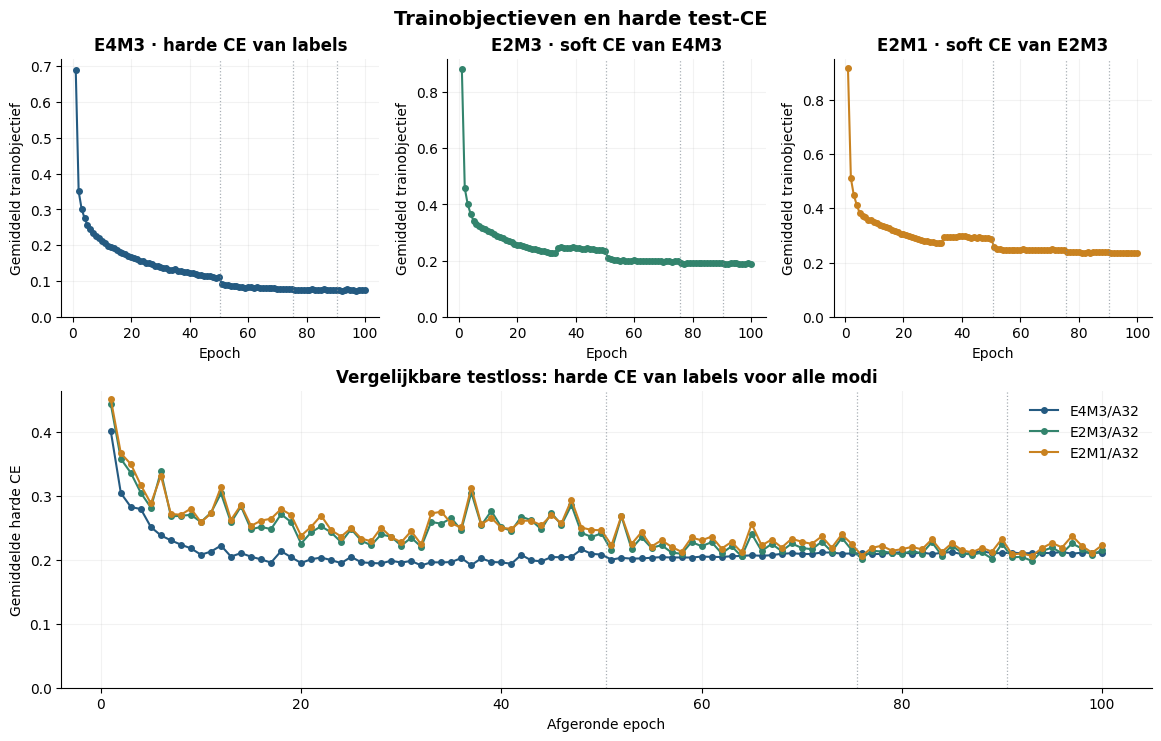

In [7]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,100,MXFP8_E4M3,10,1,19.648894,19.587431,94.871696,False,26032,"[1782, 5115, 4146, 2848, 2526, 2352, 1980, 202...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,100,MXFP6_E2M3,10,1,18.746159,19.587431,93.934388,False,26032,"[1807, 4880, 4136, 2951, 2445, 2390, 1998, 208...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,100,MXFP4_E2M1,10,1,18.815304,19.587431,93.961278,False,26032,"[1814, 4898, 4134, 2910, 2459, 2381, 2016, 209...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,63,MXFP8_E4M3,10,1,19.668101,19.587431,95.029195,False,26032,"[1779, 5120, 4134, 2872, 2508, 2369, 1973, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,63,MXFP6_E2M3,10,1,20.186693,19.587431,93.846036,False,26032,"[1670, 5255, 4196, 2804, 2632, 2414, 1903, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,63,MXFP4_E2M1,10,1,20.282729,19.587431,93.700061,False,26032,"[1661, 5280, 4229, 2794, 2631, 2398, 1909, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


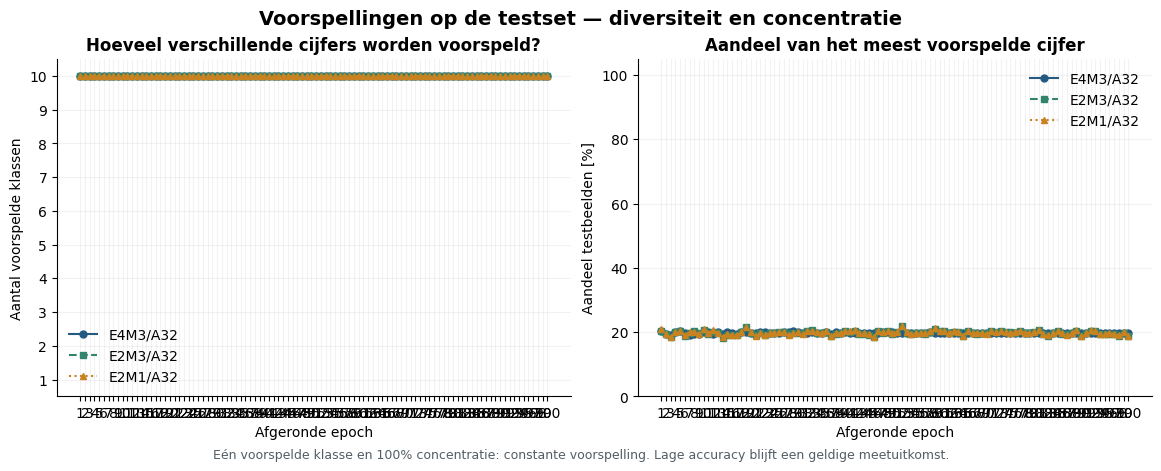

In [8]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Welke factoren worden gekozen, en bewegen de hulpwaarden?

De diagnostiek onderscheidt het leersignaal, de continue beweging van θ en de harde keuze. De negen drempels liggen op **0,5; 1,5; …; 8,5**. Een parameter kan bewegen zonder een drempel te passeren. Geen harde omschakeling is daarom geen technische FAIL.

De gestapelde grafieken tonen **alle tien factoren per laag en per epoch**, inclusief epoch 0. De histogrammen tonen de volledige θ-verdeling bij initialisatie, bij het E4M3-bestcheckpoint en bij de laatste afgeronde epoch. We onderscheiden groepen die een uiterste factor kiezen van hulpwaarden die exact op de projectiegrens 0 of 9 liggen.

De helper berekent keuzes en samenvattingen opnieuw uit de opgeslagen blokstaat en vergelijkt ze met CSV en history. De training hoeft niet alle toegestane factoren daadwerkelijk te bezoeken; de afzonderlijke codeccontroles toetsen hun bereikbaarheid.


**Laatste afgeronde epoch 100 — aantallen per factor:** ×1: **0**, ×2: **0**, ×4: **0**, ×8: **0**, ×16: **6**, ×32: **1,161**, ×64: **2,779**, ×128: **134**, ×256: **0**, ×512: **0**. Totaal: 4,080 groepen. In de laatste epoch veranderden 3,914 FP32-hulpwaarden. Over de opgeslagen training werden 389,881 harde keuzewisselingen geteld.

**Uiterste keuzes:** 0 groepen kiezen ×1 en 0 kiezen ×512. **Exact op de projectiegrens:** 0 θ-waarden zijn 0 en 0 zijn 9. Een uiterste keuze betekent dus niet automatisch dat de continue parameter op de grens vastzit.

Een groep kan binnen een epoch meerdere keren wisselen. Het aantal wissels, het aantal unieke wisselende groepen en het verschil tussen de twee epochgrenzen zijn afzonderlijke metingen. Een sprong van offset 5 naar 7 telt als één wissel met sprongafstand 2. Geen harde wissel sluit een continue θ-verplaatsing niet uit; geen van deze diagnostieken bewijst accuracywinst.

,epoch,layer,blocks,theta_min,theta_max,theta_mean,theta_std,theta_changed_blocks,theta_update_l2,count_x1,...,net_choice_changes,choice_flips_during_epoch,choice_jump_distance_during_epoch,max_choice_jump,unique_blocks_switched_during_epoch,projected_values_during_epoch,scale_grad_l2_min,scale_grad_l2_max,scale_grad_nonzero_blocks_max,scale_lr
0,1,layers.3,64,5.850802,6.162382,5.993897,0.069282,64,0.556402,0,...,0,0,0,0,0,0,0.001660,0.035356,64,0.001000
1,1,layers.6,80,5.785663,6.313862,6.000089,0.098845,80,0.884101,0,...,0,0,0,0,0,0,0.001413,0.034316,80,0.001000
2,1,layers.10,160,5.774481,6.177226,5.999722,0.072247,160,0.913868,0,...,0,0,0,0,0,0,0.001296,0.025283,160,0.001000
3,1,layers.13,288,5.824772,6.211803,6.000009,0.070784,288,1.201245,0,...,0,0,0,0,0,0,0.001238,0.020347,288,0.001000
4,1,layers.16,288,5.731654,6.198665,6.002740,0.069197,288,1.175233,0,...,0,0,0,0,0,0,0.000951,0.017856,288,0.001000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,100,layers.6,80,5.458287,6.921988,6.017774,0.420280,79,0.000182,0,...,14,426,426,1,30,0,0.010126,0.045638,80,0.000001
596,100,layers.10,160,5.161739,6.500003,6.007690,0.405591,157,0.000270,0,...,21,547,547,1,50,0,0.013546,0.050763,160,0.000001
597,100,layers.13,288,5.220516,6.561807,6.009156,0.412723,282,0.000362,0,...,24,854,854,1,92,0,0.013462,0.046645,288,0.000001
598,100,layers.16,288,4.827907,6.500005,5.995817,0.429620,281,0.000310,0,...,32,762,762,1,100,0,0.009617,0.030948,288,0.000001


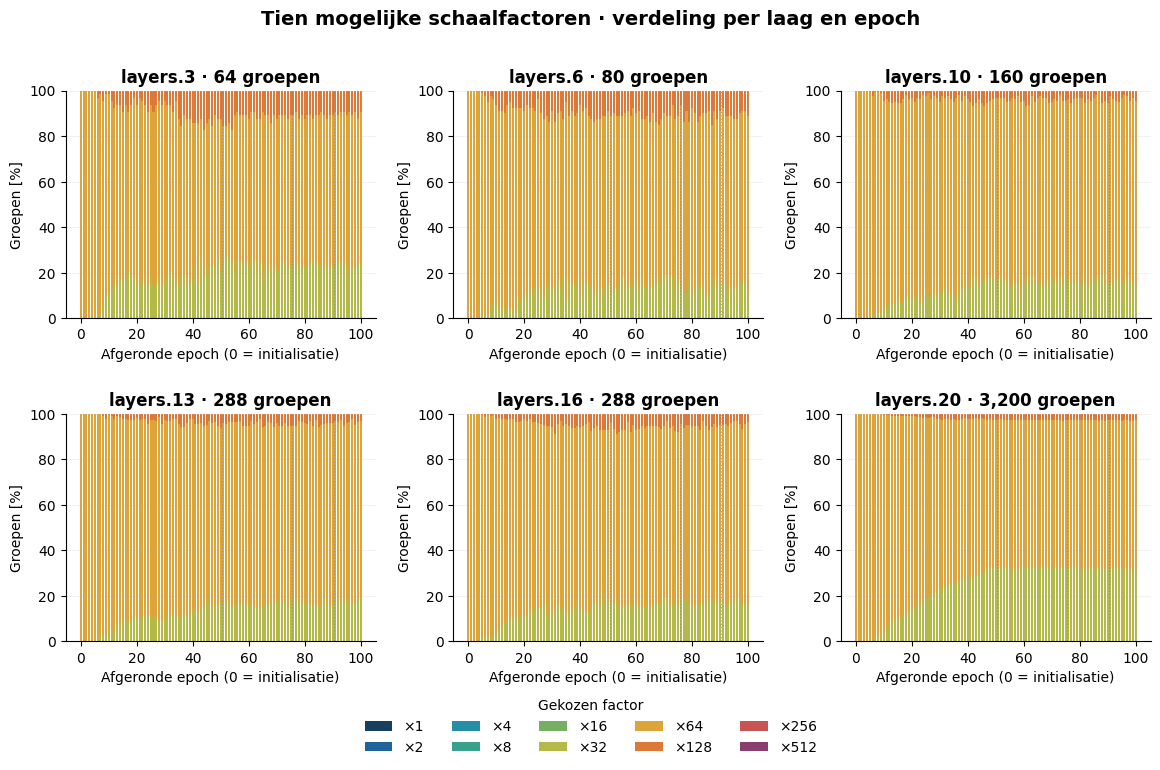

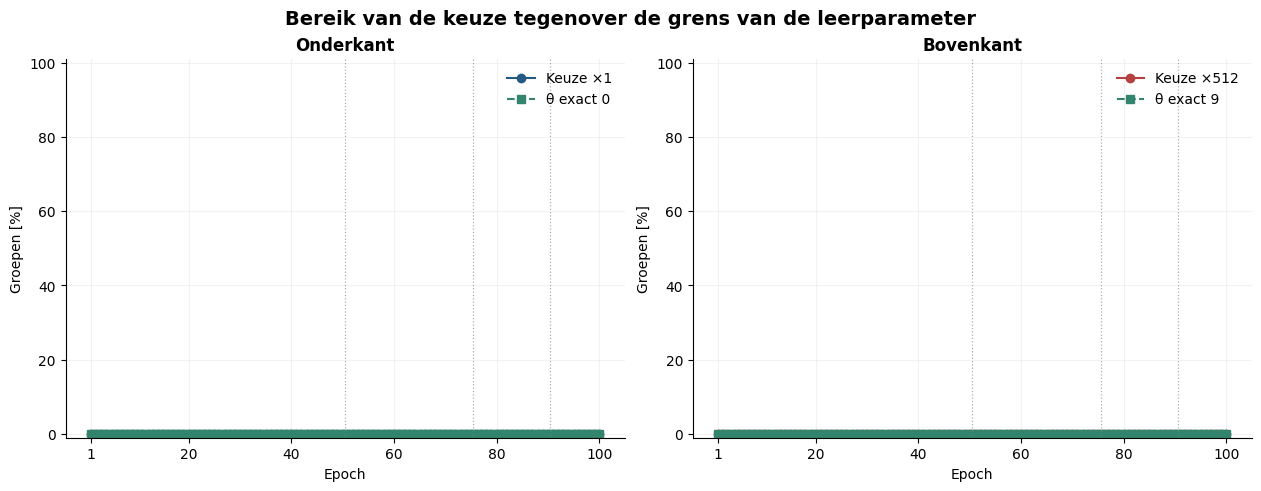

In [9]:
display(Markdown(ns.scale_learning_markdown(run)))
display(ns.scale_table(run).round(8))
figures['scale_choices'] = ns.plot_scale_choices(run)
display(figures['scale_choices'])
plt.close(figures['scale_choices'])
figures['scale_boundaries'] = ns.plot_scale_boundaries(run)
display(figures['scale_boundaries'])
plt.close(figures['scale_boundaries'])


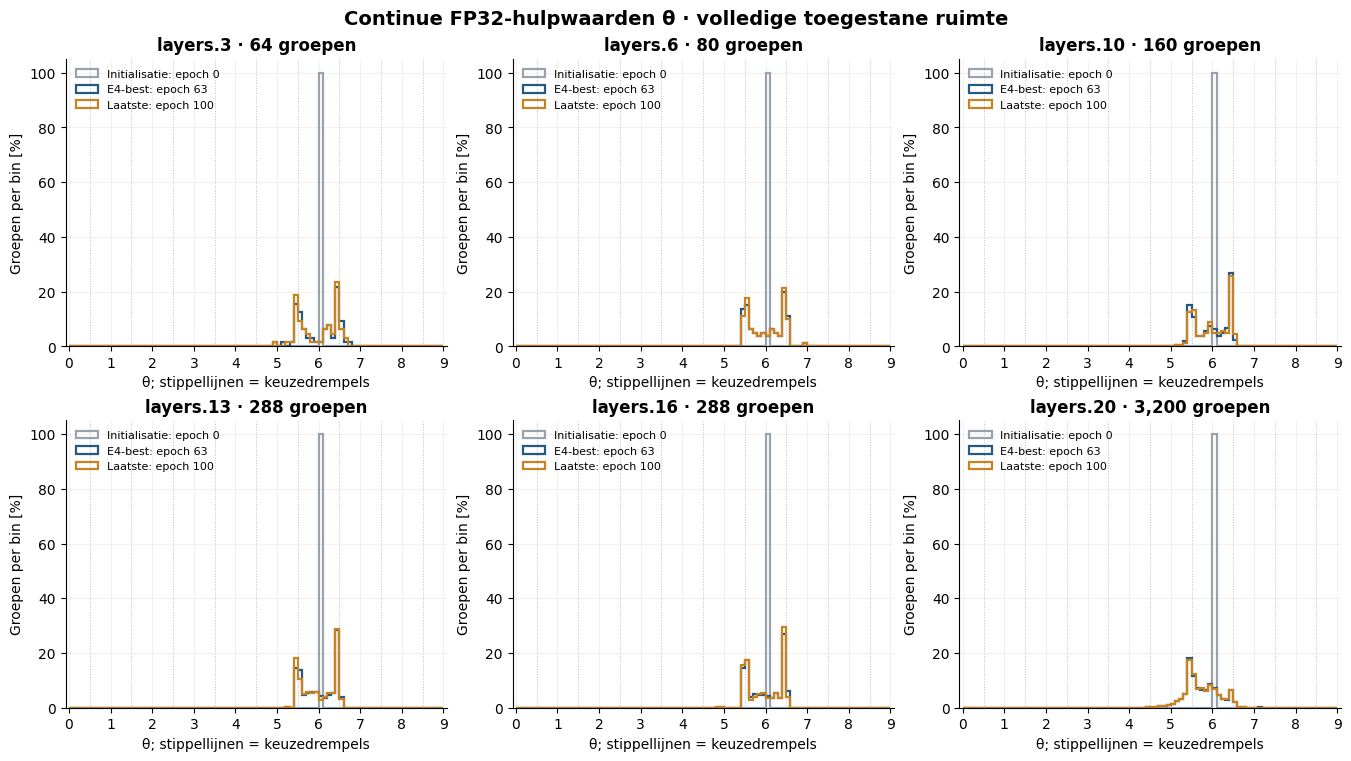

In [10]:
figures['theta_distributions'] = ns.plot_theta_distributions(run)
display(figures['theta_distributions'])
plt.close(figures['theta_distributions'])


### Wissels, spronggrootte, gradients en projectie

Iedere verandering van de harde offset na een optimizerupdate telt als één wissel. Een sprong van +5 naar +7 telt dus als **één wissel met afstand twee**. De tabel bewaart ook de som van sprongafstanden en de grootste sprong. Het aantal unieke wisselende groepen telt elke groep maximaal eenmaal per epoch; netto wijzigingen vergelijken alleen de epochgrenzen. Een groep kan meerdere keren heen en weer wisselen.

De L2-update is het netto verschil van de continue parameters. De gradientgrafiek toont de grootste waargenomen gradientnorm per laag en epoch. De projectietelling telt waarden die na Adam buiten [0,9] vielen en werden teruggezet, inclusief herhalingen. Deze diagnostieken zijn geen bewijs van accuracywinst.


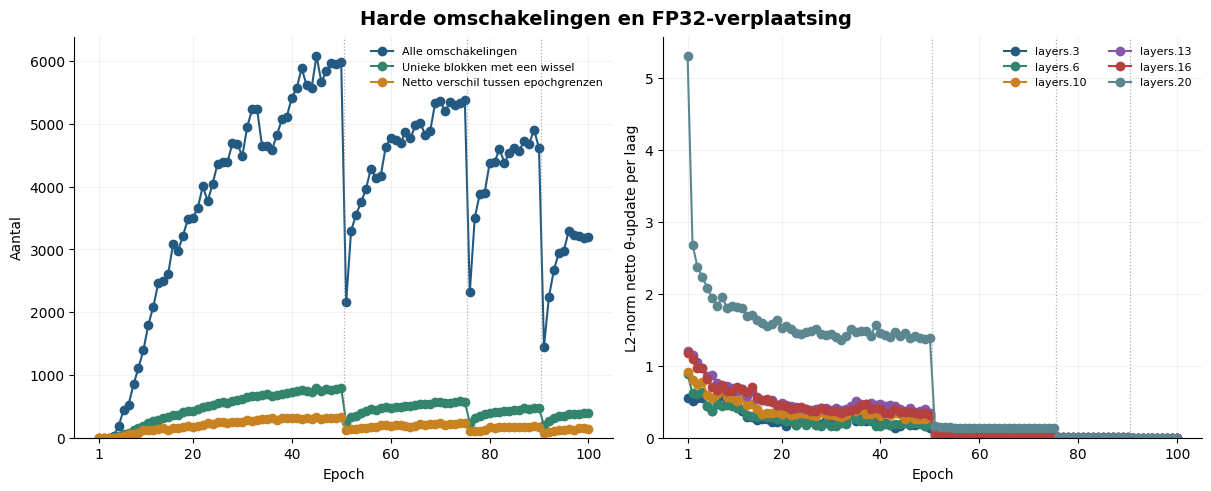

In [11]:
figures['scale_switches'] = ns.plot_scale_switches(run)
display(figures['scale_switches'])
plt.close(figures['scale_switches'])


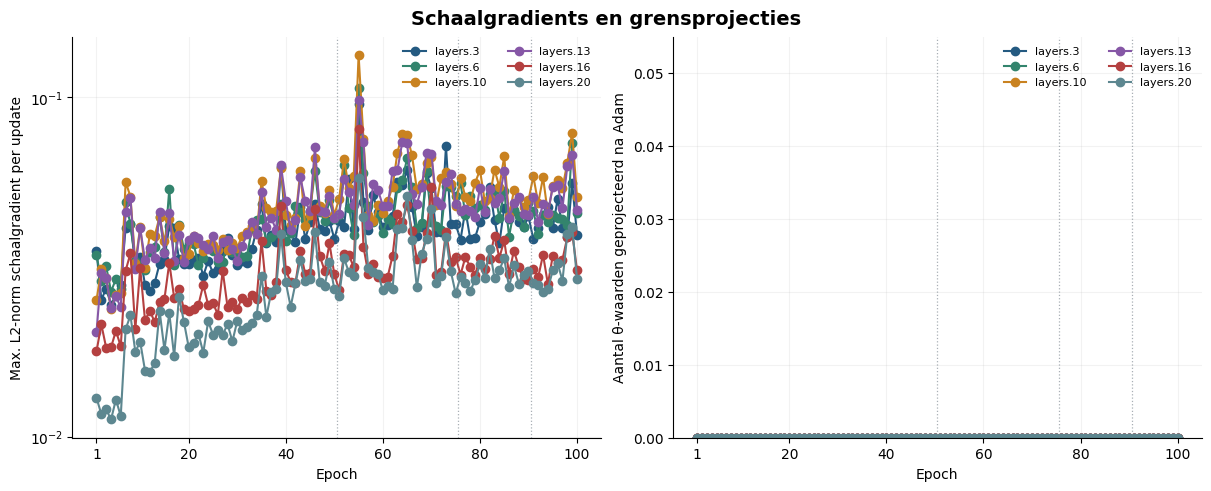

In [12]:
figures['scale_gradients'] = ns.plot_scale_gradients(run)
display(figures['scale_gradients'])
plt.close(figures['scale_gradients'])


## Gemeten trainingsduur; bij onvolledige run een afzonderlijke projectie

**Gemeten som over 100 afgeronde epochs: 5873.81 s (97.90 minuten).** Alle honderd epochs zijn aanwezig. De gemeten duur omvat train, test, epochcontroles en checkpointschrijven; een eerdere projectie wordt hiervoor niet gebruikt. Download, installatie, data-inladen, eindrapportage en sessiepauzes zijn niet inbegrepen.

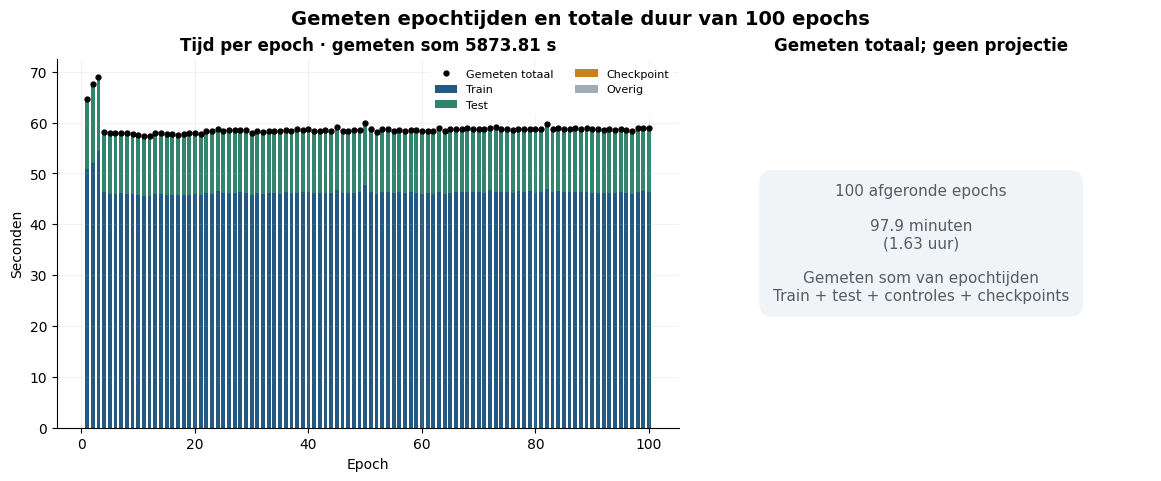

In [13]:
display(Markdown('## Gemeten trainingsduur; bij onvolledige run een afzonderlijke projectie'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

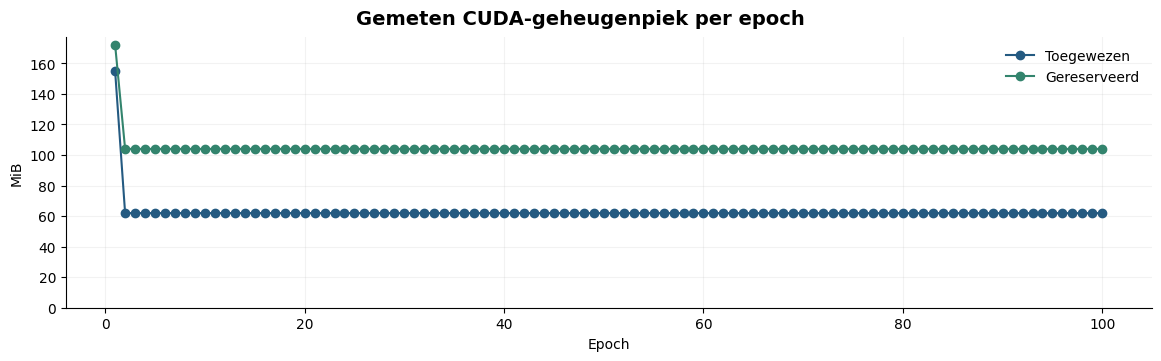

In [14]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [15]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten gecontroleerd,True
2,Geleerde schaalcorrectie ingeschakeld,True
3,Schaalkeuzes en θ-staten onafhankelijk consistent,True
4,E2M1 behoudt de E2M3-schaal,True
5,Eén E4-bron per laag en minibatch,True
6,Broncache leeg vóór iedere optimizerupdate,True
7,BN-tellers correct in elke opgeslagen epoch,True
8,Evaluatie zonder optimizerupdates,True
9,Bronbestanden ongewijzigd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.472770,torch.float32,1093,0
1,1,MXFP6_E2M3,layers.3,1728,1.472770,torch.float32,1543,0
2,1,MXFP8_E4M3,layers.3,1728,1.472770,torch.float32,1625,0
3,1,MXFP4_E2M1,layers.6,2304,1.743958,torch.float32,1419,0
4,1,MXFP6_E2M3,layers.6,2304,1.743958,torch.float32,2093,0
...,...,...,...,...,...,...,...,...
1795,100,MXFP6_E2M3,layers.16,9211,0.001919,torch.float32,146,32
1796,100,MXFP8_E4M3,layers.16,9211,0.001919,torch.float32,148,0
1797,100,MXFP4_E2M1,layers.20,98223,0.006623,torch.float32,252,48
1798,100,MXFP6_E2M3,layers.20,98223,0.006623,torch.float32,832,48


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes MX-masters afwezig,FP32-schaalproxies afwezig,Gepakte keuze-informatie [bytes],Eigen schaaloffsets,E4-bronschaal behouden,Afgeleid uit opgeslagen bron,Masters gelezen voor afleiding,Volledige testset opnieuw uitgevoerd,Bron-SHA256
0,best_E4M3_test,63,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,202009,True,True,True,2040,[0],True,False,False,False,6f5978ba64afcd7465e2be07691c81de8ac5e724c26555...
1,best_E4M3_test,63,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,169369,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,6f5978ba64afcd7465e2be07691c81de8ac5e724c26555...
2,best_E4M3_test,63,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,136793,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,6f5978ba64afcd7465e2be07691c81de8ac5e724c26555...
3,last_epoch,100,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,202009,True,True,True,2040,[0],True,False,False,False,dc62221b2933174a7badb7270ae67ba7aecafbb38e8eda...
4,last_epoch,100,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,169369,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,dc62221b2933174a7badb7270ae67ba7aecafbb38e8eda...
5,last_epoch,100,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,136793,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,dc62221b2933174a7badb7270ae67ba7aecafbb38e8eda...


## Opslagkosten van meer keuzemogelijkheden

Een compacte flexibele E4-bron bewaart nu **4 bits per groep** voor de gekozen offset. Tien mogelijkheden passen in een nibble; waarden 10–15 zijn ongeldig. Voor 4.080 groepen zijn dit **2.040 bytes**, tegenover **510 bytes** voor de binaire keuze: **1.530 bytes extra**. Een losse lagere uitvoerprecisie heeft de gekozen offset al verwerkt in zijn E8M0-schaal; daar wordt de keuze-index niet nogmaals bijgeteld.

Er blijft één FP32-parameter per groep. Parameter, gradient en twee FP32-Adam-momenten vragen analytisch **65.280 extra bytes** ten opzichte van vaste schalen, evenveel als bij de binaire leerproef. Tijdelijke buffers, activaties, optimizerstaptellers en allocatoroverhead zijn niet inbegrepen. De grafiek toont deze onderdelen afzonderlijk, niet totale VRAM of de grootte van `.pt`-bestanden.


,Variant,Keuzebits per groep,Groepen,Compacte keuzebytes,Extra FP32 theta+gradient+Adam [bytes]
0,Vaste factor,0,4080,0,0
1,Twee leerbare keuzes,1,4080,510,65280
2,Tien leerbare keuzes,4,4080,2040,65280


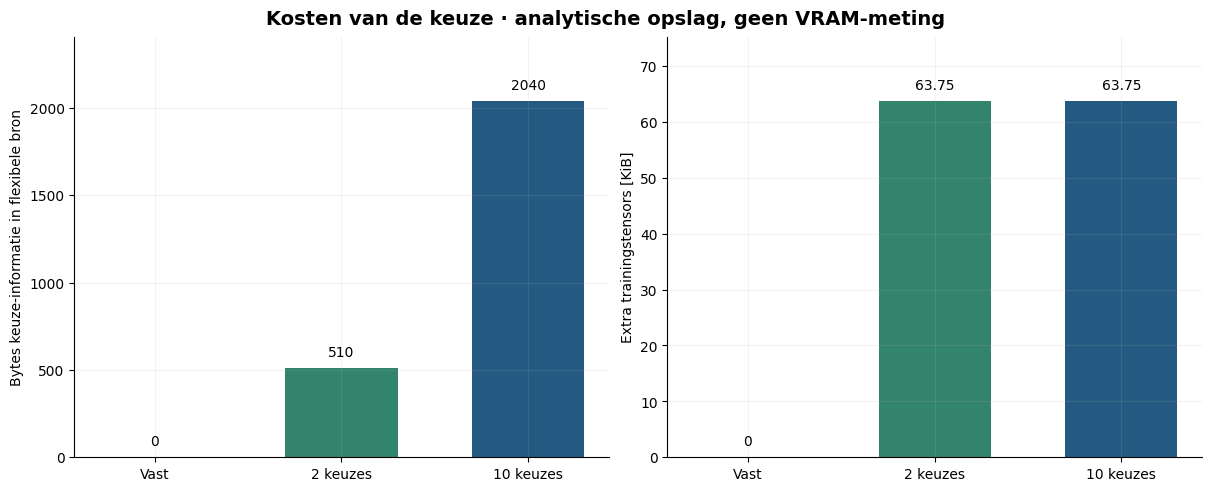

In [16]:
display(ns.storage_cost_table(run))
figures['storage_cost'] = ns.plot_storage_cost(run)
display(figures['storage_cost'])
plt.close(figures['storage_cost'])


## Interpretatie en grenzen

Tegenover de binaire leerproef zijn de **tien gehele offsets 0..9 in plaats van twee offsets 5/6** en de ruimere parametergrenzen de inhoudelijke wijziging. De groepindeling, oorspronkelijke modelinitialisatie, θ-init 6, losses, drie passes, schaalgradient en optimizerinstellingen zijn behouden. Tegenover de tienkeuzepilot verandert alleen de duur: deze run begint opnieuw en loopt door tot 100. De E4-bronschalen blijven dynamisch volgens dezelfde encoder; de gewichtsgradient blijft identity-STE naar G(W).

Meer keuzes vergroten het bereik; zij voegen geen tussenwaarden tussen ×32 en ×64 toe. Een lage accuracy, constante voorspelling of weinig harde wissels is een onderzoeksuitkomst wanneer de technische controles slagen. Bekijk accuracy, harde test-CE, voorspeldistributie en schaalgedrag samen. Dit experiment bewijst niet welk bereik, welke gradientbenadering of welk bevriestijdstip optimaal is.

**Er wordt in deze run niets bevroren op epoch 50.** Het checkpoint van50 bewaart model, θ, Adam, scheduler, RNG en historie. Een eventuele latere vriesproef kan daarmee vanaf 51 starten zonder deze tak met verder leren opnieuw te trainen. Onafhankelijke schalen per exponentbreedte blijven een afzonderlijke volgende onderzoeksrichting.

Bij honderd volledig bevestigde epochs wordt de gemeten som van epochtijden getoond; bij een onvoltooide run blijft een projectie duidelijk afzonderlijk. CUDA volgt de oorspronkelijke backend en biedt geen bitexacte herhaal- of hervatgarantie. De FP32-emulator meet geen native MX-hardwaredoorvoer of energie. De officiële testset wordt ook voor checkpointselectie gebruikt; de geselecteerde score is geen onafhankelijke eindtestschatting.


In [17]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_learned_scale10_reference100\20261104_193228_406260_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,scale_epoch_metrics.csv
